In [1]:
import numpy as np
import torch

SEED = 1234
torch.manual_seed(SEED)
torch.backends.cudnn.deterministic = True

# 0. Choosing "teacher" model

In [2]:
checkpoint = "bert-base-uncased"
task_name  = "mrpc"

# 1. Loading our mrpc part of the GLUE dataset

In [3]:
from datasets import load_dataset
from transformers import AutoTokenizer, DataCollatorWithPadding

raw_datasets = load_dataset("glue", task_name)
tokenizer = AutoTokenizer.from_pretrained(checkpoint)

/usr/local/lib/python3.10/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [4]:
import datasets
datasets.config.TORCHVISION_AVAILABLE = False

In [5]:
raw_datasets

DatasetDict({
    train: Dataset({
        features: ['sentence1', 'sentence2', 'label', 'idx'],
        num_rows: 3668
    })
    validation: Dataset({
        features: ['sentence1', 'sentence2', 'label', 'idx'],
        num_rows: 408
    })
    test: Dataset({
        features: ['sentence1', 'sentence2', 'label', 'idx'],
        num_rows: 1725
    })
})

In [6]:
raw_datasets['train']

Dataset({
    features: ['sentence1', 'sentence2', 'label', 'idx'],
    num_rows: 3668
})

In [7]:
from datasets import DatasetDict

In [8]:
raw_datasets = DatasetDict({
    "train": raw_datasets['train'],
    "validation": raw_datasets['validation'],
    "test": raw_datasets['test']
})

In [9]:
raw_datasets

DatasetDict({
    train: Dataset({
        features: ['sentence1', 'sentence2', 'label', 'idx'],
        num_rows: 3668
    })
    validation: Dataset({
        features: ['sentence1', 'sentence2', 'label', 'idx'],
        num_rows: 408
    })
    test: Dataset({
        features: ['sentence1', 'sentence2', 'label', 'idx'],
        num_rows: 1725
    })
})

In [10]:
raw_train_dataset = raw_datasets["train"]
raw_train_dataset[0]

{'sentence1': 'Amrozi accused his brother , whom he called " the witness " , of deliberately distorting his evidence .',
 'sentence2': 'Referring to him as only " the witness " , Amrozi accused his brother of deliberately distorting his evidence .',
 'label': 1,
 'idx': 0}

In [11]:
raw_train_dataset[5]['sentence1'], raw_train_dataset[5]['sentence2']

('Revenue in the first quarter of the year dropped 15 percent from the same period a year earlier .',
 "With the scandal hanging over Stewart 's company , revenue the first quarter of the year dropped 15 percent from the same period a year earlier .")

In [12]:
raw_train_dataset[5]['label']

1

In [13]:
raw_train_dataset[5]['idx']

5

In [14]:
raw_train_dataset.features

{'sentence1': Value('string'),
 'sentence2': Value('string'),
 'label': ClassLabel(names=['not_equivalent', 'equivalent']),
 'idx': Value('int32')}

# 2. Preprocess

In [15]:
def tokenize_function(example):
    return tokenizer(example["sentence1"], example["sentence2"], truncation=True)

tokenized_datasets = raw_datasets.map(tokenize_function, batched=True)
tokenized_datasets

DatasetDict({
    train: Dataset({
        features: ['sentence1', 'sentence2', 'label', 'idx', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 3668
    })
    validation: Dataset({
        features: ['sentence1', 'sentence2', 'label', 'idx', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 408
    })
    test: Dataset({
        features: ['sentence1', 'sentence2', 'label', 'idx', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 1725
    })
})

# 3. Preparing for Training

In [16]:
from transformers import DataCollatorWithPadding

data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

In [17]:
tokenized_datasets = tokenized_datasets.remove_columns(["sentence1", "sentence2", "idx"])
tokenized_datasets = tokenized_datasets.rename_column("label", "labels")
tokenized_datasets.set_format("torch")
tokenized_datasets["train"].column_names

['labels', 'input_ids', 'token_type_ids', 'attention_mask']

In [18]:
from torch.utils.data import DataLoader

train_dataloader = DataLoader(
    tokenized_datasets["train"], shuffle=True, batch_size=32, collate_fn=data_collator
)

val_dataloader = DataLoader(
    tokenized_datasets["validation"], batch_size=32, collate_fn=data_collator
)

eval_dataloader = DataLoader(
    tokenized_datasets["test"], batch_size=32, collate_fn=data_collator
)

In [19]:
for batch in train_dataloader:
    break
{k: v.shape for k, v in batch.items()}

{'labels': torch.Size([32]),
 'input_ids': torch.Size([32, 100]),
 'token_type_ids': torch.Size([32, 100]),
 'attention_mask': torch.Size([32, 100])}

# 4. Load Model

In [20]:
import sys
sys.path.insert(0, '../')

In [21]:
from Bert_model.modeling_bert_para_sharing import BertForSequenceClassification

In [22]:
# id2label, label2id dicts for the outputs for the model
labels = tokenized_datasets["train"].features["labels"].names
num_labels = len(labels)
label2id, id2label = dict(), dict()
for i, label in enumerate(labels):
    label2id[label] = str(i)
    id2label[str(i)] = label

In [23]:
model = BertForSequenceClassification.from_pretrained(
    checkpoint,
    num_labels=num_labels,
    id2label=id2label,
    label2id=label2id,
    output_hidden_states=True,
    output_attentions=True
)

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at bert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


In [24]:
model.set_use_module_grafting(False)
model.set_use_scc_status(False)

In [25]:
outputs = model(**batch)
print(outputs.loss, outputs.logits.shape)

tensor(1.2996, grad_fn=<NllLossBackward0>) torch.Size([32, 2])


In [26]:
device = torch.device("cuda:1") if torch.cuda.is_available() else torch.device("cpu")
model.to(device)

device

device(type='cuda', index=1)

### Load Trained Weights

In [27]:
load_path = '../glue_fine_tune/weights/'
best_weight = torch.load(load_path + f'bert-{task_name}.pt', map_location=device)
model.load_state_dict(best_weight['model_state_dict'])

<All keys matched successfully>

In [28]:
from train_eval_func import eval_loop

In [29]:
eval_loop(model, val_dataloader, task_name, device)

({'accuracy': 0.8676470588235294, 'f1': 0.9093959731543624},
 0.8802372308877798)

In [30]:
from CKA import CKAEvaluator

cka_eval = CKAEvaluator(device)

In [31]:
def adjacent_similarity_stats(
    similarity_scores, 
    thresold = 0.80,
    disp_sim_score=True, 
    disp_group_count=True
):
    adj_similarities = []
    for i in range(1, len(similarity_scores)):
        adj_similarities.append(similarity_scores[i-1][i])

    if disp_sim_score:
        print("Similarity Scores:", adj_similarities)

    high_pair_count = 0
    for pair in adj_similarities:
        if pair > thresold:
            high_pair_count += 1
    
    if disp_group_count:
        print("Number of High Similar Pairs:", high_pair_count)

    return adj_similarities, high_pair_count

# 5. Layer Drop

In [32]:
effected_performance = {
    "top_drop": [],
    "alt_drop": [],
    "sim_drop": [],
    "para_shar_alt": [],
    "para_shar_sim": [],
    "para_shar_top": [],
    "mha_share":[],
    "mlp_share": []
}

### Top Layer Drop

In [34]:
for i in range(6):
    del model.bert.encoder.layer[-1]

    affected_score = eval_loop(
        model, val_dataloader, task_name, device
    )[0]

    print("Number of layer:", len(model.bert.encoder.layer))
    print(affected_score)
    print("")

    effected_performance["top_drop"].append(
        (len(model.bert.encoder.layer), affected_score)
    )

Number of layer: 11
{'accuracy': 0.8799019607843137, 'f1': 0.9170896785109983}

Number of layer: 10
{'accuracy': 0.8725490196078431, 'f1': 0.9100346020761245}

Number of layer: 9
{'accuracy': 0.7892156862745098, 'f1': 0.8259109311740891}

Number of layer: 8
{'accuracy': 0.3161764705882353, 'f1': 0.0}

Number of layer: 7
{'accuracy': 0.3161764705882353, 'f1': 0.0}

Number of layer: 6
{'accuracy': 0.3161764705882353, 'f1': 0.0}



In [44]:
del model

In [45]:
torch.cuda.empty_cache()

In [46]:
model = BertForSequenceClassification.from_pretrained(
    checkpoint,
    num_labels=num_labels,
    id2label=id2label,
    label2id=label2id,
    output_hidden_states=True,
    output_attentions=True
)

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at bert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


In [47]:
model.to(device)

device

device(type='cuda', index=1)

In [48]:
model.load_state_dict(best_weight['model_state_dict'])

<All keys matched successfully>

In [49]:
eval_loop(model, val_dataloader, task_name, device)

({'accuracy': 0.8676470588235294, 'f1': 0.9093959731543624},
 0.8802372308877798)

### Top Layer Parameter Sharing

In [31]:
run_layer = [
    {
        "times": 1,
        "run_heads": True,
        "run_wo": True,
        "run_ffn": True,
    }
    for _ in range(12)
]

run_layer

[{'times': 1, 'run_heads': True, 'run_wo': True, 'run_ffn': True},
 {'times': 1, 'run_heads': True, 'run_wo': True, 'run_ffn': True},
 {'times': 1, 'run_heads': True, 'run_wo': True, 'run_ffn': True},
 {'times': 1, 'run_heads': True, 'run_wo': True, 'run_ffn': True},
 {'times': 1, 'run_heads': True, 'run_wo': True, 'run_ffn': True},
 {'times': 1, 'run_heads': True, 'run_wo': True, 'run_ffn': True},
 {'times': 1, 'run_heads': True, 'run_wo': True, 'run_ffn': True},
 {'times': 1, 'run_heads': True, 'run_wo': True, 'run_ffn': True},
 {'times': 1, 'run_heads': True, 'run_wo': True, 'run_ffn': True},
 {'times': 1, 'run_heads': True, 'run_wo': True, 'run_ffn': True},
 {'times': 1, 'run_heads': True, 'run_wo': True, 'run_ffn': True},
 {'times': 1, 'run_heads': True, 'run_wo': True, 'run_ffn': True}]

In [32]:
eval_loop(model, val_dataloader, task_name, device, run_layer=run_layer)

({'accuracy': 0.8676470588235294, 'f1': 0.9093959731543624},
 0.8802372308877798)

In [34]:
for i in range(6):
    del model.bert.encoder.layer[-1]

    new_times = run_layer[-1]["times"] + 1
    del run_layer[-1]
    run_layer[-1]["times"] = new_times

    affected_score = eval_loop(
        model, val_dataloader, task_name, device, run_layer=run_layer
    )[0]

    print("Number of layers:", len(model.bert.encoder.layer))
    print(affected_score)
    print("")

    effected_performance["para_shar_top"].append(
        (len(model.bert.encoder.layer), affected_score)
    )

Number of layers: 11
{'accuracy': 0.875, 'f1': 0.9142857142857143}

Number of layers: 10
{'accuracy': 0.8627450980392157, 'f1': 0.9060402684563759}

Number of layers: 9
{'accuracy': 0.8725490196078431, 'f1': 0.9078014184397163}

Number of layers: 8
{'accuracy': 0.3161764705882353, 'f1': 0.0}

Number of layers: 7
{'accuracy': 0.40441176470588236, 'f1': 0.2476780185758514}

Number of layers: 6
{'accuracy': 0.6544117647058824, 'f1': 0.6817155756207675}



In [35]:
run_layer

[{'times': 1, 'run_heads': True, 'run_wo': True, 'run_ffn': True},
 {'times': 1, 'run_heads': True, 'run_wo': True, 'run_ffn': True},
 {'times': 1, 'run_heads': True, 'run_wo': True, 'run_ffn': True},
 {'times': 1, 'run_heads': True, 'run_wo': True, 'run_ffn': True},
 {'times': 1, 'run_heads': True, 'run_wo': True, 'run_ffn': True},
 {'times': 7, 'run_heads': True, 'run_wo': True, 'run_ffn': True}]

In [36]:
del model

In [37]:
torch.cuda.empty_cache()

In [38]:
model = BertForSequenceClassification.from_pretrained(
    checkpoint,
    num_labels=num_labels,
    id2label=id2label,
    label2id=label2id,
    output_hidden_states=True,
    output_attentions=True
)

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at bert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


In [39]:
model.to(device)

device

device(type='cuda', index=1)

In [40]:
model.load_state_dict(best_weight['model_state_dict'])

<All keys matched successfully>

In [41]:
eval_loop(model, val_dataloader, task_name, device)

({'accuracy': 0.8676470588235294, 'f1': 0.9093959731543624},
 0.8802372308877798)

### Alt Layer Drop

In [51]:
for i in range(11, 0, -2):
    model.bert.encoder.layer.pop(i)

    affected_score = eval_loop(
        model, val_dataloader, task_name, device
    )[0]

    print("Drop Layer Index:", i)
    print("Number of remaining layers:", len(model.bert.encoder.layer))
    print(affected_score)
    print("")

    effected_performance["alt_drop"].append(
        (len(model.bert.encoder.layer), affected_score)
    )

Drop Layer Index: 11
Number of remaining layers: 11
{'accuracy': 0.8799019607843137, 'f1': 0.9170896785109983}

Drop Layer Index: 9
Number of remaining layers: 10
{'accuracy': 0.8725490196078431, 'f1': 0.9084507042253521}

Drop Layer Index: 7
Number of remaining layers: 9
{'accuracy': 0.8578431372549019, 'f1': 0.896797153024911}

Drop Layer Index: 5
Number of remaining layers: 8
{'accuracy': 0.47058823529411764, 'f1': 0.3898305084745763}

Drop Layer Index: 3
Number of remaining layers: 7
{'accuracy': 0.32107843137254904, 'f1': 0.014234875444839857}

Drop Layer Index: 1
Number of remaining layers: 6
{'accuracy': 0.3161764705882353, 'f1': 0.0}



In [52]:
del model

In [53]:
torch.cuda.empty_cache()

In [54]:
model = BertForSequenceClassification.from_pretrained(
    checkpoint,
    num_labels=num_labels,
    id2label=id2label,
    label2id=label2id,
    output_hidden_states=True,
    output_attentions=True
)

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at bert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


In [55]:
model.to(device)

device

device(type='cuda', index=1)

In [56]:
model.load_state_dict(best_weight['model_state_dict'])

<All keys matched successfully>

In [57]:
eval_loop(model, val_dataloader, task_name, device)

({'accuracy': 0.8676470588235294, 'f1': 0.9093959731543624},
 0.8802372308877798)

### Alt Layer Parameter Sharing

In [58]:
run_layer = [
    {
        "times": 1,
        "run_heads": True,
        "run_wo": True,
        "run_ffn": True,
    }
    for _ in range(12)
]

run_layer

[{'times': 1, 'run_heads': True, 'run_wo': True, 'run_ffn': True},
 {'times': 1, 'run_heads': True, 'run_wo': True, 'run_ffn': True},
 {'times': 1, 'run_heads': True, 'run_wo': True, 'run_ffn': True},
 {'times': 1, 'run_heads': True, 'run_wo': True, 'run_ffn': True},
 {'times': 1, 'run_heads': True, 'run_wo': True, 'run_ffn': True},
 {'times': 1, 'run_heads': True, 'run_wo': True, 'run_ffn': True},
 {'times': 1, 'run_heads': True, 'run_wo': True, 'run_ffn': True},
 {'times': 1, 'run_heads': True, 'run_wo': True, 'run_ffn': True},
 {'times': 1, 'run_heads': True, 'run_wo': True, 'run_ffn': True},
 {'times': 1, 'run_heads': True, 'run_wo': True, 'run_ffn': True},
 {'times': 1, 'run_heads': True, 'run_wo': True, 'run_ffn': True},
 {'times': 1, 'run_heads': True, 'run_wo': True, 'run_ffn': True}]

In [59]:
eval_loop(model, val_dataloader, task_name, device, run_layer=run_layer)

({'accuracy': 0.8676470588235294, 'f1': 0.9093959731543624},
 0.8802372308877798)

In [60]:
for i in range(11, 0, -2):
    model.bert.encoder.layer.pop(i)
    run_layer.pop(i)
    run_layer[i-1]['times'] += 1
    
    affected_score = eval_loop(
        model, val_dataloader, task_name, device, run_layer=run_layer
    )[0]

    print("Drop Layer Index:", i)
    print("Number of remaining layers:", len(model.bert.encoder.layer))
    print(affected_score)
    print("")

    effected_performance["para_shar_alt"].append(
        (len(model.bert.encoder.layer), affected_score)
    )

Drop Layer Index: 11
Number of remaining layers: 11
{'accuracy': 0.875, 'f1': 0.9142857142857143}

Drop Layer Index: 9
Number of remaining layers: 10
{'accuracy': 0.8774509803921569, 'f1': 0.9140893470790378}

Drop Layer Index: 7
Number of remaining layers: 9
{'accuracy': 0.8406862745098039, 'f1': 0.8922056384742952}

Drop Layer Index: 5
Number of remaining layers: 8
{'accuracy': 0.8308823529411765, 'f1': 0.8747731397459165}

Drop Layer Index: 3
Number of remaining layers: 7
{'accuracy': 0.8088235294117647, 'f1': 0.8631578947368421}

Drop Layer Index: 1
Number of remaining layers: 6
{'accuracy': 0.6446078431372549, 'f1': 0.6868250539956804}



In [62]:
del model

In [63]:
torch.cuda.empty_cache()

In [64]:
model = BertForSequenceClassification.from_pretrained(
    checkpoint,
    num_labels=num_labels,
    id2label=id2label,
    label2id=label2id,
    output_hidden_states=True,
    output_attentions=True
)

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at bert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


In [65]:
model.to(device)

device

device(type='cuda', index=1)

In [66]:
model.load_state_dict(best_weight['model_state_dict'])

<All keys matched successfully>

In [67]:
eval_loop(model, val_dataloader, task_name, device)

({'accuracy': 0.8676470588235294, 'f1': 0.9093959731543624},
 0.8802372308877798)

### MHA Share

In [33]:
reps_similarity, atts_similarity, mha_similarity, pre_wo_similarity, sub_similarity, pre_wo_sub_similarity = cka_eval.subLayer_interleaved_pairwise(
    model, 
    train_dataloader, 
    device, 
    only_cls_token=True, 
    max_iter=115
)

CKA Sublayer Evaluation: 100%|██████████| 115/115 [01:17<00:00,  1.48it/s]


In [34]:
subs_stats = cka_eval.similarity_stats(sub_similarity)
print("  Sublayer Similarity Stats:")
print(f"    Average: {subs_stats['average']:.6f}")
print(f"    Highest: {subs_stats['max']:.6f}")
print(f"    Lowest:  {subs_stats['min']:.6f}")

  Sublayer Similarity Stats:
    Average: 0.948331
    Highest: 0.996554
    Lowest:  0.788115


In [35]:
import matplotlib.pyplot as plt
import seaborn as sn

Text(50.722222222222214, 0.5, 'Layer')

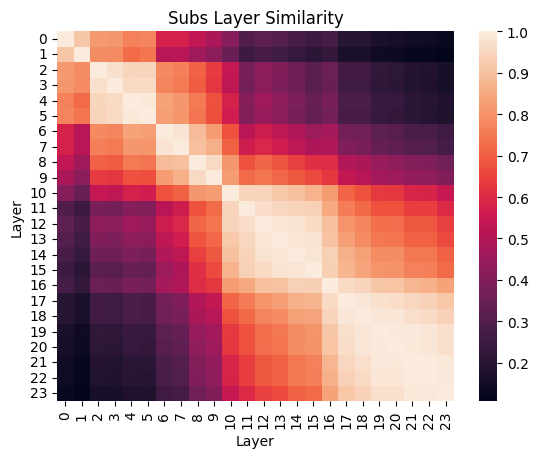

In [36]:
title = "Subs Layer Similarity"
plt.title(title)
sn.heatmap(data = sub_similarity)
plt.xlabel("Layer")
plt.ylabel("Layer")

In [37]:
def mha_mlp_similarity_stats(cls_reps_similarity):
    adj_similarities = []
    for i in range(1, len(cls_reps_similarity), 2):
        adj_similarities.append(cls_reps_similarity[i-1][i])

    argmax = int(np.argmax(adj_similarities))
    argmin = int(np.argmin(adj_similarities))
    
    return {
        'average': float(np.mean(adj_similarities)),
        'max': float(adj_similarities[argmax]),
        'argmax': argmax,
        'min': float(adj_similarities[argmin]),
        'argmin': argmin,
        'adj_similarities': adj_similarities
    }

In [38]:
mha_mlp_stats = mha_mlp_similarity_stats(sub_similarity)

In [39]:
mha_mlp_stats['adj_similarities']

[0.909702,
 0.9726945,
 0.9917159,
 0.97967553,
 0.95544887,
 0.9464082,
 0.9853821,
 0.98456144,
 0.96139705,
 0.98762923,
 0.9923215,
 0.9948107]

In [40]:
mha_mlp_stats['average']

0.9718123078346252

In [41]:
high_pair_count = 0
for score in mha_mlp_stats['adj_similarities']:
    if score > 0.98:
        high_pair_count += 1
high_pair_count

6

In [41]:
run_layer = [
    {
        "times": 1,
        "run_heads": True,
        "run_wo": {"run": True, "times": 1},
        "run_ffn": True,
    }
    for _ in range(12)
]

run_layer

[{'times': 1,
  'run_heads': True,
  'run_wo': {'run': True, 'times': 1},
  'run_ffn': True},
 {'times': 1,
  'run_heads': True,
  'run_wo': {'run': True, 'times': 1},
  'run_ffn': True},
 {'times': 1,
  'run_heads': True,
  'run_wo': {'run': True, 'times': 1},
  'run_ffn': True},
 {'times': 1,
  'run_heads': True,
  'run_wo': {'run': True, 'times': 1},
  'run_ffn': True},
 {'times': 1,
  'run_heads': True,
  'run_wo': {'run': True, 'times': 1},
  'run_ffn': True},
 {'times': 1,
  'run_heads': True,
  'run_wo': {'run': True, 'times': 1},
  'run_ffn': True},
 {'times': 1,
  'run_heads': True,
  'run_wo': {'run': True, 'times': 1},
  'run_ffn': True},
 {'times': 1,
  'run_heads': True,
  'run_wo': {'run': True, 'times': 1},
  'run_ffn': True},
 {'times': 1,
  'run_heads': True,
  'run_wo': {'run': True, 'times': 1},
  'run_ffn': True},
 {'times': 1,
  'run_heads': True,
  'run_wo': {'run': True, 'times': 1},
  'run_ffn': True},
 {'times': 1,
  'run_heads': True,
  'run_wo': {'run': True,

In [66]:
for idx, score in reversed(list(enumerate(mha_mlp_stats['adj_similarities']))):
    if score > 0.98:
        run_layer[idx]["times"] = 2
        run_layer[idx]["run_ffn"] = False
        print(idx)

        affected_score = eval_loop(
            model, val_dataloader, task_name, device, run_layer=run_layer
        )[0]
    
        print("Drop Layer Index:", i)
        print("Number of remaining layers:", len(model.bert.encoder.layer))
        print(affected_score)
        print("")

11
Drop Layer Index: 1
Number of remaining layers: 12
{'accuracy': 0.8725490196078431, 'f1': 0.912751677852349}

10
Drop Layer Index: 1
Number of remaining layers: 12
{'accuracy': 0.8308823529411765, 'f1': 0.8878048780487805}

9
Drop Layer Index: 1
Number of remaining layers: 12
{'accuracy': 0.8602941176470589, 'f1': 0.8994708994708994}

7
Drop Layer Index: 1
Number of remaining layers: 12
{'accuracy': 0.6666666666666666, 'f1': 0.6822429906542056}

6
Drop Layer Index: 1
Number of remaining layers: 12
{'accuracy': 0.3161764705882353, 'f1': 0.0}

2
Drop Layer Index: 1
Number of remaining layers: 12
{'accuracy': 0.3161764705882353, 'f1': 0.0}



In [67]:
run_layer

[{'times': 1,
  'run_heads': True,
  'run_wo': {'run': True, 'times': 1},
  'run_ffn': True},
 {'times': 1,
  'run_heads': True,
  'run_wo': {'run': True, 'times': 1},
  'run_ffn': True},
 {'times': 2,
  'run_heads': True,
  'run_wo': {'run': True, 'times': 1},
  'run_ffn': False},
 {'times': 1,
  'run_heads': True,
  'run_wo': {'run': True, 'times': 1},
  'run_ffn': True},
 {'times': 1,
  'run_heads': True,
  'run_wo': {'run': True, 'times': 1},
  'run_ffn': True},
 {'times': 1,
  'run_heads': True,
  'run_wo': {'run': True, 'times': 1},
  'run_ffn': True},
 {'times': 2,
  'run_heads': True,
  'run_wo': {'run': True, 'times': 1},
  'run_ffn': False},
 {'times': 2,
  'run_heads': True,
  'run_wo': {'run': True, 'times': 1},
  'run_ffn': False},
 {'times': 1,
  'run_heads': True,
  'run_wo': {'run': True, 'times': 1},
  'run_ffn': True},
 {'times': 2,
  'run_heads': True,
  'run_wo': {'run': True, 'times': 1},
  'run_ffn': False},
 {'times': 2,
  'run_heads': True,
  'run_wo': {'run': T

In [58]:
eval_loop(model, val_dataloader, task_name, device, run_layer=run_layer)

({'accuracy': 0.3161764705882353, 'f1': 0.0}, 0.7300758178417499)

In [42]:
for idx, score in reversed(list(enumerate(mha_mlp_stats['adj_similarities']))):
    if score > 0.98:
        run_layer[idx]["times"] = 2
        run_layer[idx]["run_heads"] = False
        print(idx)

        affected_score = eval_loop(
            model, val_dataloader, task_name, device, run_layer=run_layer
        )[0]
    
        print("Drop Layer Index:", i)
        print("Number of remaining layers:", len(model.bert.encoder.layer))
        print(affected_score)
        print("")

11
Drop Layer Index: 1
Number of remaining layers: 12
{'accuracy': 0.8504901960784313, 'f1': 0.8991735537190083}

10
Drop Layer Index: 1
Number of remaining layers: 12
{'accuracy': 0.8553921568627451, 'f1': 0.9018302828618968}

9
Drop Layer Index: 1
Number of remaining layers: 12
{'accuracy': 0.8480392156862745, 'f1': 0.8980263157894737}

7
Drop Layer Index: 1
Number of remaining layers: 12
{'accuracy': 0.7696078431372549, 'f1': 0.8246268656716418}

6
Drop Layer Index: 1
Number of remaining layers: 12
{'accuracy': 0.3235294117647059, 'f1': 0.0547945205479452}

2
Drop Layer Index: 1
Number of remaining layers: 12
{'accuracy': 0.3284313725490196, 'f1': 0.035211267605633804}



### Alt Merge Share

In [35]:
from layer_merge_helper import merge_mha, merge_ff, reorder_merged_layer_heads, reorder_layer_neurons
from structure_prune_helper import compute_importance_scores, register_importance_masks, remove_importance_masks

In [36]:
register_importance_masks(model, device, register_mha=True, register_mlp=True)

  Layer 0: Registered (12 heads, 3072 neurons)
  Layer 1: Registered (12 heads, 3072 neurons)
  Layer 2: Registered (12 heads, 3072 neurons)
  Layer 3: Registered (12 heads, 3072 neurons)
  Layer 4: Registered (12 heads, 3072 neurons)
  Layer 5: Registered (12 heads, 3072 neurons)
  Layer 6: Registered (12 heads, 3072 neurons)
  Layer 7: Registered (12 heads, 3072 neurons)
  Layer 8: Registered (12 heads, 3072 neurons)
  Layer 9: Registered (12 heads, 3072 neurons)
  Layer 10: Registered (12 heads, 3072 neurons)
  Layer 11: Registered (12 heads, 3072 neurons)


BertForSequenceClassification(
  (bert): BertModel(
    (embeddings): BertEmbeddings(
      (word_embeddings): Embedding(30522, 768, padding_idx=0)
      (position_embeddings): Embedding(512, 768)
      (token_type_embeddings): Embedding(2, 768)
      (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (encoder): BertEncoder(
      (layer): ModuleList(
        (0-11): 12 x BertLayer(
          (attention): BertAttention(
            (self): BertSelfAttention(
              (query): Linear(in_features=768, out_features=768, bias=True)
              (key): Linear(in_features=768, out_features=768, bias=True)
              (value): Linear(in_features=768, out_features=768, bias=True)
              (dropout): Dropout(p=0.1, inplace=False)
            )
            (output): BertSelfOutput(
              (dense): Linear(in_features=768, out_features=768, bias=True)
              (LayerNorm): LayerNorm((768,), eps=1e-12,

In [39]:
run_layer = [
    {
        "times": 1,
        "run_heads": True,
        "run_wo": {"run": True, "times": 1},
        "run_ffn": True,
    }
    for _ in range(12)
]

run_layer

[{'times': 1,
  'run_heads': True,
  'run_wo': {'run': True, 'times': 1},
  'run_ffn': True},
 {'times': 1,
  'run_heads': True,
  'run_wo': {'run': True, 'times': 1},
  'run_ffn': True},
 {'times': 1,
  'run_heads': True,
  'run_wo': {'run': True, 'times': 1},
  'run_ffn': True},
 {'times': 1,
  'run_heads': True,
  'run_wo': {'run': True, 'times': 1},
  'run_ffn': True},
 {'times': 1,
  'run_heads': True,
  'run_wo': {'run': True, 'times': 1},
  'run_ffn': True},
 {'times': 1,
  'run_heads': True,
  'run_wo': {'run': True, 'times': 1},
  'run_ffn': True},
 {'times': 1,
  'run_heads': True,
  'run_wo': {'run': True, 'times': 1},
  'run_ffn': True},
 {'times': 1,
  'run_heads': True,
  'run_wo': {'run': True, 'times': 1},
  'run_ffn': True},
 {'times': 1,
  'run_heads': True,
  'run_wo': {'run': True, 'times': 1},
  'run_ffn': True},
 {'times': 1,
  'run_heads': True,
  'run_wo': {'run': True, 'times': 1},
  'run_ffn': True},
 {'times': 1,
  'run_heads': True,
  'run_wo': {'run': True,

In [40]:
head_importance, neuron_importance = compute_importance_scores(model, train_dataloader, device, compute_heads=True, compute_ffn=True)

Computing importance (heads + FFN): 100%|██████████| 115/115 [00:11<00:00, 10.32it/s]


In [41]:
for layer in [10, 8, 6, 4, 2, 0]:
    src = model.bert.encoder.layer[layer]
    tgt = model.bert.encoder.layer[layer + 1]

    # raw scores in, reorder in place
    reorder_merged_layer_heads(src, head_importance[layer],     device)
    reorder_merged_layer_heads(tgt, head_importance[layer + 1], device)
    reorder_layer_neurons(src, neuron_importance[layer],     device)
    reorder_layer_neurons(tgt, neuron_importance[layer + 1], device)

    # scores now in the new (descending) order
    head_imp1,   _ = torch.sort(head_importance[layer],       descending=True)
    head_imp2,   _ = torch.sort(head_importance[layer + 1],   descending=True)
    neuron_imp1, _ = torch.sort(neuron_importance[layer],     descending=True)
    neuron_imp2, _ = torch.sort(neuron_importance[layer + 1], descending=True)

    merge_mha(model, src, tgt, head_imp1, head_imp2, device)
    merge_ff(model, src, tgt, neuron_imp1, neuron_imp2, device)

    run_layer[layer + 1]["times"] = 2
    del model.bert.encoder.layer[layer]
    del run_layer[layer]

    model.eval()
    with torch.no_grad():
        score = eval_loop(model, val_dataloader, task_name, device,
                          run_layer=run_layer)[0]

    print("Merged layers:", layer, "->", layer + 1)
    print("Remaining layers:", len(model.bert.encoder.layer))
    print(score, "\n")

Reordered 12 heads, new order: [0, 5, 10, 8, 7, 1, 9, 3, 6, 2, 11, 4]
Reordered 12 heads, new order: [2, 9, 8, 7, 4, 5, 10, 11, 6, 0, 3, 1]
  Reordered 3072 neurons
  Reordered 3072 neurons
6 6
2062 1010
Merged layers: 10 -> 11
Remaining layers: 11
{'accuracy': 0.8799019607843137, 'f1': 0.9156626506024096} 

Reordered 12 heads, new order: [8, 1, 10, 7, 9, 3, 0, 11, 2, 4, 5, 6]
Reordered 12 heads, new order: [5, 2, 10, 11, 7, 8, 4, 0, 6, 1, 3, 9]
  Reordered 3072 neurons
  Reordered 3072 neurons
6 6
2180 892
Merged layers: 8 -> 9
Remaining layers: 10
{'accuracy': 0.8651960784313726, 'f1': 0.905982905982906} 

Reordered 12 heads, new order: [0, 7, 5, 8, 4, 1, 6, 9, 2, 10, 11, 3]
Reordered 12 heads, new order: [5, 0, 8, 10, 1, 2, 9, 4, 11, 3, 7, 6]
  Reordered 3072 neurons
  Reordered 3072 neurons
8 4
1622 1450
Merged layers: 6 -> 7
Remaining layers: 9
{'accuracy': 0.8578431372549019, 'f1': 0.8986013986013986} 

Reordered 12 heads, new order: [3, 2, 9, 4, 1, 5, 8, 10, 0, 6, 7, 11]
Reorder

In [ ]:
run_layer = [
    {
        "times": 1,
        "run_heads": True,
        "run_wo": {"run": True, "times": 1},
        "run_ffn": True,
    }
    for _ in range(12)
]

In [43]:
head_importance, neuron_importance = compute_importance_scores(model, train_dataloader, device, compute_heads=True, compute_ffn=True)

Computing importance (heads + FFN): 100%|██████████| 115/115 [00:11<00:00, 10.32it/s]


In [44]:
head_imp1, indices1 = torch.sort(head_importance[11], descending=True)
head_imp2, indices2 = torch.sort(head_importance[10], descending=True)

In [48]:
reorder_merged_layer_heads(model.bert.encoder.layer[10], head_imp2, device)

Reordered 12 heads, new order: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11]


BertLayer(
  (attention): BertAttention(
    (self): BertSelfAttention(
      (query): Linear(in_features=768, out_features=768, bias=True)
      (key): Linear(in_features=768, out_features=768, bias=True)
      (value): Linear(in_features=768, out_features=768, bias=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (output): BertSelfOutput(
      (dense): Linear(in_features=768, out_features=768, bias=True)
      (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
  )
  (intermediate): BertIntermediate(
    (dense): Linear(in_features=768, out_features=3072, bias=True)
    (intermediate_act_fn): GELUActivation()
  )
  (output): BertOutput(
    (dense): Linear(in_features=3072, out_features=768, bias=True)
    (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
    (dropout): Dropout(p=0.1, inplace=False)
  )
)

In [49]:
reorder_merged_layer_heads(model.bert.encoder.layer[11], head_imp1, device)

Reordered 12 heads, new order: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11]


BertLayer(
  (attention): BertAttention(
    (self): BertSelfAttention(
      (query): Linear(in_features=768, out_features=768, bias=True)
      (key): Linear(in_features=768, out_features=768, bias=True)
      (value): Linear(in_features=768, out_features=768, bias=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (output): BertSelfOutput(
      (dense): Linear(in_features=768, out_features=768, bias=True)
      (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
  )
  (intermediate): BertIntermediate(
    (dense): Linear(in_features=768, out_features=3072, bias=True)
    (intermediate_act_fn): GELUActivation()
  )
  (output): BertOutput(
    (dense): Linear(in_features=3072, out_features=768, bias=True)
    (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
    (dropout): Dropout(p=0.1, inplace=False)
  )
)

In [64]:
neuron_imp1, indices1 = torch.sort(neuron_importance[11], descending=True)        
neuron_imp2, indices1 = torch.sort(neuron_importance[10], descending=True)

In [65]:
reorder_layer_neurons(model.bert.encoder.layer[11], neuron_imp1, device)

  Reordered 3072 neurons


BertLayer(
  (attention): BertAttention(
    (self): BertSelfAttention(
      (query): Linear(in_features=768, out_features=768, bias=True)
      (key): Linear(in_features=768, out_features=768, bias=True)
      (value): Linear(in_features=768, out_features=768, bias=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (output): BertSelfOutput(
      (dense): Linear(in_features=768, out_features=768, bias=True)
      (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
  )
  (intermediate): BertIntermediate(
    (dense): Linear(in_features=768, out_features=3072, bias=True)
    (intermediate_act_fn): GELUActivation()
  )
  (output): BertOutput(
    (dense): Linear(in_features=3072, out_features=768, bias=True)
    (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
    (dropout): Dropout(p=0.1, inplace=False)
  )
)

In [66]:
reorder_layer_neurons(model.bert.encoder.layer[10], neuron_imp2, device)

  Reordered 3072 neurons


BertLayer(
  (attention): BertAttention(
    (self): BertSelfAttention(
      (query): Linear(in_features=768, out_features=768, bias=True)
      (key): Linear(in_features=768, out_features=768, bias=True)
      (value): Linear(in_features=768, out_features=768, bias=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (output): BertSelfOutput(
      (dense): Linear(in_features=768, out_features=768, bias=True)
      (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
  )
  (intermediate): BertIntermediate(
    (dense): Linear(in_features=768, out_features=3072, bias=True)
    (intermediate_act_fn): GELUActivation()
  )
  (output): BertOutput(
    (dense): Linear(in_features=3072, out_features=768, bias=True)
    (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
    (dropout): Dropout(p=0.1, inplace=False)
  )
)

In [67]:
eval_loop(model, val_dataloader, task_name, device)

({'accuracy': 0.8700980392156863, 'f1': 0.9106239460370995},
 0.8232049919091738)

In [51]:
merge_mha(model, model.bert.encoder.layer[11], model.bert.encoder.layer[10], head_imp1, head_imp2, device)

6 6


In [62]:
model.bert.encoder.layer[10].attention.self.query.weight[64*6:] == model.bert.encoder.layer[11].attention.self.query.weight[:64*6]

tensor([[True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        ...,
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True]], device='cuda:1')

In [68]:
merge_ff(model, model.bert.encoder.layer[11], model.bert.encoder.layer[10], neuron_imp1, neuron_imp2, device)

1010 2062


In [91]:
model.bert.encoder.layer[10].intermediate.dense.weight[2062:] == model.bert.encoder.layer[11].intermediate.dense.weight[:1010]

tensor([[True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        ...,
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True]], device='cuda:1')